In [4]:
import pandas as pd, lightgbm, xgboost, networkx
import os; print(os.listdir("../data"))

['txs_edgelist.csv', 'test.csv', 'train.csv', 'sample_submission.csv']


In [5]:
import sys; print(sys.executable)

/Users/dorislai/Downloads/bt4012_kaggle_competition/bt4012-kaggle/.venv/bin/python


# Phase 1: Data check

Goal: confirm the basics of the data before building anything.

1. Load the files and look at their shape and columns
2. Label counts (illicit / licit / unlabeled)
3. Time steps: which are in train vs test, and how the illicit rate changes over time
4. Missing values and constant columns
5. Basic graph statistics (edges, degree distribution)

## 1. Load the files

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../data"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
edges = pd.read_csv(f"{DATA_DIR}/txs_edgelist.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print("train:     ", train.shape)
print("test:      ", test.shape)
print("edges:     ", edges.shape)
print("sample_sub:", sample_sub.shape)

train:      (141772, 168)
test:       (15329, 168)
edges:      (234355, 2)
sample_sub: (15329, 2)


In [ ]:
# columns difference between train and test
print("In train but not test:", sorted(set(train.columns) - set(test.columns)))
print("In test but not train:", sorted(set(test.columns) - set(train.columns)))

# anonymized feature columns
feature_cols = [c for c in train.columns if c.startswith("feat_")]
print("Number of feature columns:", len(feature_cols))

# data types
print(train.dtypes.value_counts())

train.head()

In train but not test: ['label']
In test but not train: ['index']
Number of feature columns: 165
float64    166
int64        2
Name: count, dtype: int64


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


In [ ]:
# txId is the transaction ID. Check its uniqueness and that train and test do not share transactions.
print("Duplicate txId in train:", train["txId"].duplicated().sum())
print("Duplicate txId in test: ", test["txId"].duplicated().sum())
print("txId in both train and test:", len(set(train["txId"]) & set(test["txId"])))

# For prediction submission: Check that test['index'] lines up row by row with the sample submission
print("test index equals sample_sub index:", (test["index"].values == sample_sub["index"].values).all())

Duplicate txId in train: 0
Duplicate txId in test:  0
txId in both train and test: 0
test index equals sample_sub index: True


## 2. Label counts

`label` is the target. `NaN` means the transaction is unlabeled.

In [ ]:
label_counts = train["label"].value_counts(dropna=False)
print(label_counts)
print()
print("Share of train rows:")
print((label_counts / len(train)).round(4))

# Illicit rate
print()
print("Illicit rate among labeled rows:", round(train["label"].mean(), 4))

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

Share of train rows:
label
NaN    0.7797
0.0    0.1946
1.0    0.0257
Name: count, dtype: float64

Illicit rate among labeled rows: 0.1167


## 3. Time steps

The test set is from future time periods, so the validation split will have to be by time.
Here we look at which time steps are in train and test, how many labeled rows each one has,
and how the illicit rate moves over time.

In [10]:
print("Train time steps:", train["time_step"].min(), "to", train["time_step"].max(),
      "(", train["time_step"].nunique(), "steps )")
print("Test time steps: ", test["time_step"].min(), "to", test["time_step"].max(),
      "(", test["time_step"].nunique(), "steps )")

Train time steps: 1 to 35 ( 35 steps )
Test time steps:  36 to 49 ( 14 steps )


In [ ]:
# One row per training time step
per_step = train.groupby("time_step").agg(
    n_rows=("txId", "size"),          # all transactions in the step
    n_labeled=("label", "count"),     
    n_illicit=("label", "sum"),       
)
per_step["labeled_share"] = per_step["n_labeled"] / per_step["n_rows"]
per_step["illicit_rate"] = per_step["n_illicit"] / per_step["n_labeled"]

# Number of test rows per test time step
test_per_step = test.groupby("time_step").size().rename("n_rows")

pd.set_option("display.max_rows", 100)
display(per_step.round(3))
display(test_per_step.to_frame().T)

,n_rows,n_labeled,n_illicit,labeled_share,illicit_rate
time_step,,,,,
1,7880,2147,17.0,0.272,0.008
2,4544,1117,18.0,0.246,0.016
3,6621,1279,11.0,0.193,0.009
4,5693,1440,30.0,0.253,0.021
5,6803,1882,8.0,0.277,0.004
6,4328,485,5.0,0.112,0.010
7,6048,1203,102.0,0.199,0.085
8,4457,1165,67.0,0.261,0.058
9,4996,778,248.0,0.156,0.319


time_step,36,37,38,39,40,41,42,43,44,45,46,47,48,49
n_rows,1708,498,756,1183,1211,1132,2154,1370,1591,1221,712,846,471,476


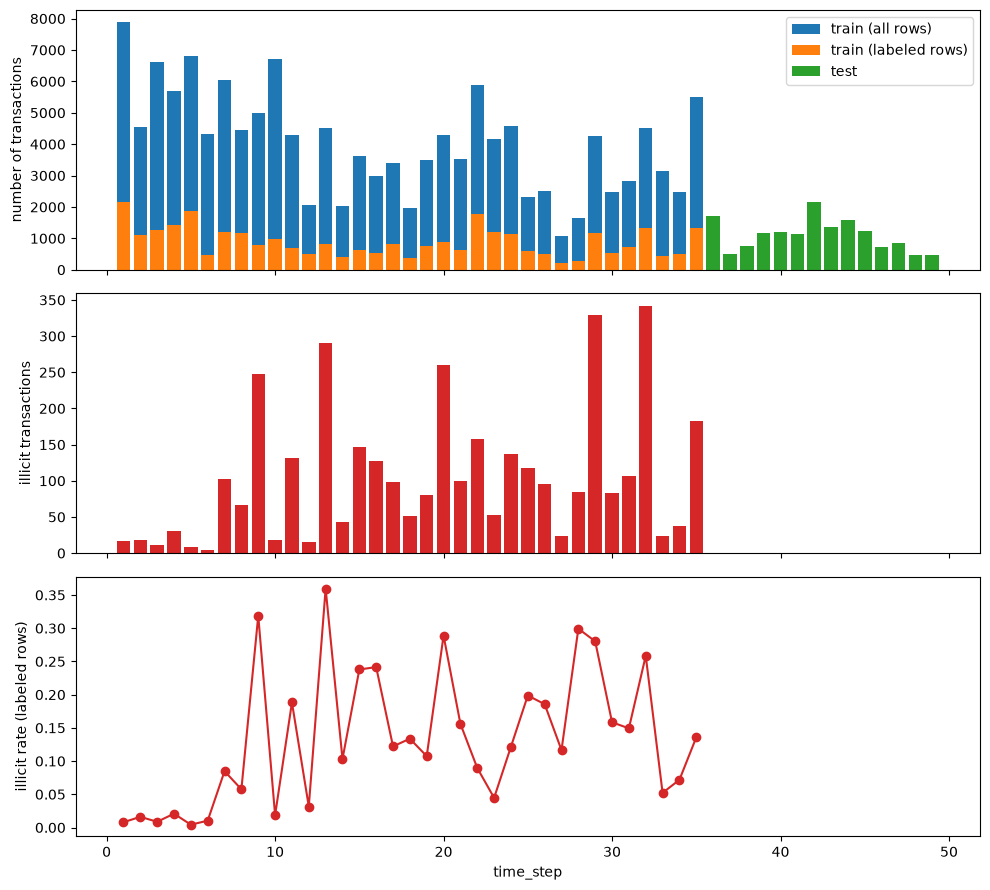

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Rows per time step, train and test on the same axis
axes[0].bar(per_step.index, per_step["n_rows"], label="train (all rows)")
axes[0].bar(per_step.index, per_step["n_labeled"], label="train (labeled rows)")
axes[0].bar(test_per_step.index, test_per_step.values, label="test")
axes[0].set_ylabel("number of transactions")
axes[0].legend()

# Number of illicit transactions per time step
axes[1].bar(per_step.index, per_step["n_illicit"], color="tab:red")
axes[1].set_ylabel("illicit transactions")

# Illicit rate among labeled rows per time step
axes[2].plot(per_step.index, per_step["illicit_rate"], marker="o", color="tab:red")
axes[2].set_ylabel("illicit rate (labeled rows)")
axes[2].set_xlabel("time_step")

plt.tight_layout()
plt.show()

## 4. Missing values and constant columns

In [ ]:
# Missing values in the feature columns 
train_missing = train[feature_cols].isna().sum()
test_missing = test[feature_cols].isna().sum()
print("Feature columns with missing values in train:", (train_missing > 0).sum())
print("Feature columns with missing values in test: ", (test_missing > 0).sum())
print("Total missing feature values, train:", train_missing.sum(), " test:", test_missing.sum())

# Infinite values
print("Infinite values in train features:", np.isinf(train[feature_cols].values).sum())
print("Infinite values in test features: ", np.isinf(test[feature_cols].values).sum())

# Columns with a single value carry no information
n_unique = train[feature_cols].nunique()
print("Constant feature columns in train:", list(n_unique[n_unique <= 1].index))

# Columns with very few distinct values may be flags or categories rather than continuous
print()
print("Feature columns with the fewest distinct values:")
print(n_unique.sort_values().head(10))

Feature columns with missing values in train: 0
Feature columns with missing values in test:  0
Total missing feature values, train: 0  test: 0
Infinite values in train features: 0
Infinite values in test features:  0
Constant feature columns in train: []

Feature columns with the fewest distinct values:
feat_112      8
feat_113      8
feat_3        8
feat_148      9
feat_149      9
feat_15      26
feat_160     54
feat_7      102
feat_118    166
feat_14     216
dtype: int64


In [ ]:
# Summary statistics for the features
train[feature_cols].describe().T[["mean", "std", "min", "max"]].describe()

## 5. Graph statistics

Each row of the edge list `(txId1, txId2)` means an output of `txId1` was spent as an input of `txId2`.

In [ ]:
print("Number of edges:", len(edges))
print("Duplicate edges:", edges.duplicated().sum())
print("Self loops:     ", (edges["txId1"] == edges["txId2"]).sum())

all_tx = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]])
edge_nodes = set(edges["txId1"]) | set(edges["txId2"])
known_nodes = set(all_tx["txId"])
print("Transactions in train + test:           ", len(known_nodes))
print("Transactions that appear in an edge:    ", len(edge_nodes))
print("Edge endpoints missing from train/test: ", len(edge_nodes - known_nodes))
print("Transactions with no edges at all:      ", len(known_nodes - edge_nodes))

Number of edges: 234355
Duplicate edges: 0
Self loops:      0
Transactions in train + test:            157101
Transactions that appear in an edge:     203769
Edge endpoints missing from train/test:  46668
Transactions with no edges at all:       0


In [ ]:
# Some edge endpoints are transactions that are not in train or test, so we have no features, time step or label for them.
step_of = all_tx.set_index("txId")["time_step"]   # lookup: txId -> time_step
step1 = edges["txId1"].map(step_of)               # NaN if txId1 is not in train/test
step2 = edges["txId2"].map(step_of)               # NaN if txId2 is not in train/test

n_known = step1.notna().astype(int) + step2.notna().astype(int)   # 0, 1 or 2 known endpoints
print("Edges by number of endpoints found in train/test:")
print(n_known.value_counts().sort_index())

Edges by number of endpoints found in train/test:
0     34192
1     24245
2    175918
Name: count, dtype: int64


Edges with both endpoints known: 175918
  of which the endpoints are in different time steps: 0


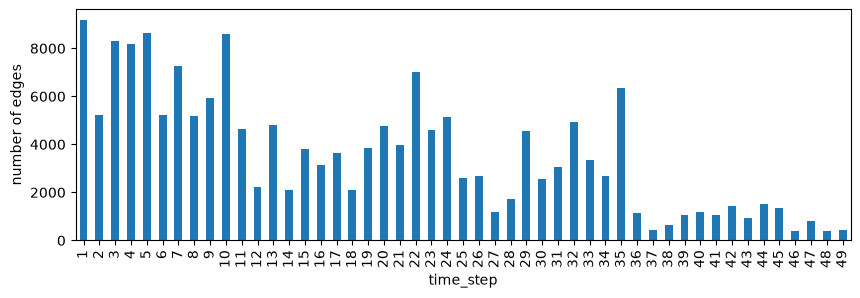

In [ ]:
# Connected transactions share a time step.
# Check this on the edges where both endpoints are known
both_known = n_known == 2
print("Edges with both endpoints known:", both_known.sum())
print("  of which the endpoints are in different time steps:",
      (step1[both_known] != step2[both_known]).sum())

# Number of these edges inside each time step
edges_per_step = step1[both_known].astype(int).value_counts().sort_index()
edges_per_step.plot(kind="bar", figsize=(10, 3), ylabel="number of edges", xlabel="time_step")
plt.show()

,in_degree,out_degree
count,157101.00,157101.00
mean,1.24,1.16
std,4.34,1.94
min,0.00,0.00
50%,1.00,1.00
90%,2.00,2.00
99%,11.00,6.00
max,284.00,472.00


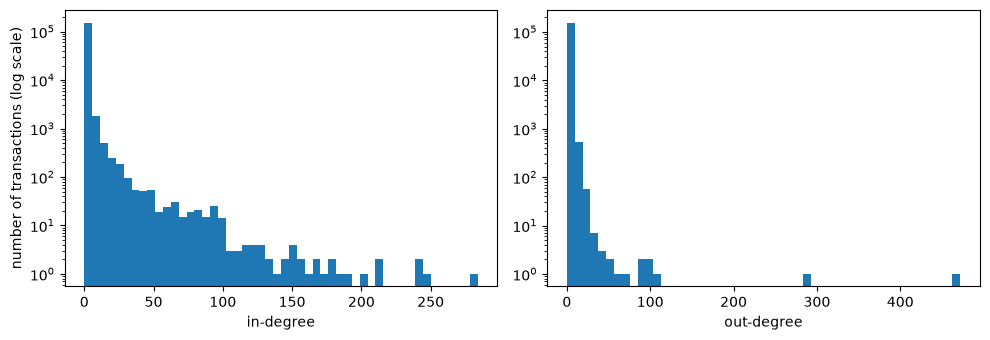

In [ ]:
# In-degree = number of edges pointing into a transaction 
# Out-degree = number of edges leaving a transaction 
in_deg = edges["txId2"].value_counts()
out_deg = edges["txId1"].value_counts()

# Build one table for every transaction.
deg = all_tx[["txId"]].copy()
deg["in_degree"] = deg["txId"].map(in_deg).fillna(0).astype(int)
deg["out_degree"] = deg["txId"].map(out_deg).fillna(0).astype(int)

display(deg[["in_degree", "out_degree"]].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

# Degree distributions are heavy tailed, so use a log scale on the y axis
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(deg["in_degree"], bins=50, log=True)
axes[0].set_xlabel("in-degree")
axes[0].set_ylabel("number of transactions (log scale)")
axes[1].hist(deg["out_degree"], bins=50, log=True)
axes[1].set_xlabel("out-degree")
plt.tight_layout()
plt.show()

In [ ]:
# Check whether degree differs by label 
labeled = train.loc[train["label"].notna(), ["txId", "label"]].merge(deg, on="txId")
labeled.groupby("label")[["in_degree", "out_degree"]].agg(["mean", "median", "max"]).round(2)

in_degree             out_degree            
           mean median  max       mean median  max
label                                             
0.0        1.83    1.0  284       1.15    1.0  472
1.0        1.25    1.0  173       0.75    1.0    2

## Findings

- **Files and columns:**
  - Train has 141,772 rows and test has 15,329 rows. Both have `txId`, `time_step` and 165 numeric
    features (`feat_1` to `feat_165`). Train also has `label`; test also has `index`.
  - `txId` is unique in both files and no transaction appears in both train and test.
  - `test['index']` matches the sample submission row by row, so predictions can be saved in test's row order.
- **Labels:**
  - `1` = illicit (3,644 rows, 2.6% of train), `0` = licit (27,591 rows, 19.5%), `NaN` = unlabeled (110,537 rows, 78.0%).
  - Among labeled rows the illicit rate is 11.7%, so the classes are imbalanced (about 1 illicit to 7.6 licit).
  - Only about 22% of the training rows can be used for supervised training; the rest are unlabeled.
- **Time steps (train vs test, illicit rate over time):**
  - Train covers time steps 1 to 35 and test covers 36 to 49, with no overlap. The test set is entirely in the future.
  - The illicit rate is not stable over time. Steps 1 to 6 are all at about 2% or lower, then it jumps
    around between about 4% and 36% (for example 36% in step 13, 5% in step 33, 14% in step 35).
  - Some steps have very few illicit rows (5 in step 6, 8 in step 5), so the AUC on a single step would be noisy.
  - Each step has between about 200 and 2,100 labeled rows.
- **Missing values / data issues:**
  - No missing or infinite values in any feature column, in train or test. No constant columns.
  - Features look standardized already (means near 0, standard deviations near 1), with some large positive outliers.
  - A few features have very few distinct values (`feat_3`, `feat_112`, `feat_113` have 8; `feat_148`, `feat_149` have 9),
    so they may be counts or categories rather than continuous values.
- **Graph:**
  - 234,355 edges, with no duplicates and no self loops. Every train and test transaction appears in at least one edge.
  - 46,668 transactions in the edge list are in neither train nor test, so they have no features, time step or label.
    24,245 edges have one such endpoint and 34,192 edges have both.
  - For the 175,918 edges where both endpoints are known, both endpoints are always in the same time step.
    So no edge connects a training transaction to a test transaction.
  - Degree is heavily skewed: the median in-degree and out-degree are both 1, but the maximums are 284 and 472.
  - In the labeled rows, illicit transactions have lower degree on average than licit ones
    (mean in-degree 1.25 vs 1.83, mean out-degree 0.75 vs 1.15), and no illicit transaction has out-degree above 2.
- **What this means for the validation split:**
  - The split has to be by time, because the test set is 14 later time steps that training never sees.
  - Because the illicit rate changes so much between steps, validating on one step would be unreliable;
    the validation set needs several steps.
  - Graph features can be computed for test in the same way as for train, since each time step is its own
    separate piece of the graph.
  
